# Analyse RAMS d'une flotte de rames voyageurs – 1. Nettoyage des données

> **Données synthétiques**, générées pour l'exercice. Elles ne proviennent d'aucun exploitant réel.

**Contexte :** historique de maintenance de 30 rames voyageurs sur 8 systèmes,
de janvier 2023 à décembre 2025 (4 098 interventions brutes).

**Objectif :** préparer des données fiables pour l'analyse RAMS (notebook 2) et la modélisation (notebook 3).

**Principales corrections :**
- 45 doublons supprimés ;
- catégories harmonisées (systèmes, types d'intervention, pannes) et dates au format mixte converties ;
- valeurs impossibles neutralisées : 8 lignes avec durée/immobilisation négatives, 6 coûts aberrants, 19 immobilisations incohérentes,
  18 types d'intervention réclassés;
- principe retenu : aucune intervention réelle supprimée, aucune valeur inventée, chaque correction tracée
  dans une colonne dédiée.

**Sortie :** `maintenance_rames_clean.csv` (4 053 interventions).

**Plan :**
1. Chargement, 2. Doublons, 3. Catégories 4. Dates, 5. Valeurs impossibles, 6. Valeurs extrêmes, 7. Type mal étiquetés, 8. Coûts, 9. Incohérences entre colonnes, 10. Valeurs manquantes, 11. Récapitulatif et export

# RAMS Analysis of a Passenger Train Fleet – 1. Data Cleaning

> **Synthetic data**, generated for this exercise. It does not come from any real operator.

**Context:** maintenance history of 30 passenger trainsets across 8 systems,
from January 2023 to December 2025 (4,098 raw interventions).

**Objective:** prepare reliable data for RAMS analysis and modelling.

**Main corrections:**
- 45 duplicates removed;
- categories harmonised (systems, intervention types, failures) and mixed-format dates converted;
- impossible values neutralised: negative durations, 6 outlier costs, 19 inconsistent downtimes,
  11 mislabelled intervention types;
- principle: no real intervention deleted, no value invented, every correction tracked in a dedicated column.

**Output:** `maintenance_rames_clean.csv` (4,053 interventions), used by the exploration notebook.

In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/oularealamako/raw-data/maintenance_rames_2023_2025.csv


## 1. Loading & first look – Chargement et premier diagnostic

In [ ]:
chemin = "../data/maintenance_rames_2023_2025.csv"
df = pd.read_csv(chemin, sep =';', decimal =',')

print(df.shape)
df.head()


(4098, 10)


,Matériel,Système,Date intervention,Type intervention,Durée intervention (h),Panne associée,Temps d'immobilisation (h),Coût (€),Technicien,Commentaire
0,R006,Signalisation embarquée,17/03/2025,Préventive,2.0,Non,3.5,565.0,Atelier Vénissieux,Remplacement préventif pièces d'usure
1,R007,Toilettes,18/07/2024,Corrective,0.9,Oui,4.1,235.0,Atelier Vénissieux,Réservoir plein
2,R023,Toilettes,30/12/2024,Préventive,1.3,Non,2.0,122.0,Atelier Lyon-Perrache,Remplacement préventif pièces d'usure
3,R024,Pantographe,01/03/2023,Préventive,2.6,Non,3.8,419.0,Atelier Vénissieux,Remplacement préventif pièces d'usure
4,R011,Climatisation,14/10/2025,Préventive,2.6,Non,3.8,334.0,NaN,Visite périodique


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4098 entries, 0 to 4097
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Matériel                    4098 non-null   object 
 1   Système                     4098 non-null   object 
 2   Date intervention           4098 non-null   object 
 3   Type intervention           4098 non-null   object 
 4   Durée intervention (h)      4017 non-null   float64
 5   Panne associée              4098 non-null   object 
 6   Temps d'immobilisation (h)  4038 non-null   float64
 7   Coût (€)                    3978 non-null   float64
 8   Technicien                  4015 non-null   object 
 9   Commentaire                 3893 non-null   object 
dtypes: float64(3), object(7)
memory usage: 320.3+ KB


In [4]:
df.describe()

,Durée intervention (h),Temps d'immobilisation (h),Coût (€)
count,4017.000000,4038.000000,3978.000000
mean,2.974185,8.153789,832.175214
std,2.434955,8.949954,4608.190268
min,-4.800000,-2.000000,61.000000
25%,1.500000,3.200000,254.000000
50%,2.300000,5.100000,448.000000
75%,3.400000,9.400000,714.500000
max,40.000000,97.500000,144085.000000


In [5]:
# Valeurs manquantes par colonne (nombre et %)
pd.DataFrame({"nb_NaN": df.isnull().sum(),
              "pct_NaN": (df.isnull().mean() * 100).round(1)})

,nb_NaN,pct_NaN
Matériel,0,0.0
Système,0,0.0
Date intervention,0,0.0
Type intervention,0,0.0
Durée intervention (h),81,2.0
Panne associée,0,0.0
Temps d'immobilisation (h),60,1.5
Coût (€),120,2.9
Technicien,83,2.0
Commentaire,205,5.0


**Premières observations :**
- 4 098 lignes et 10 colonnes ; valeurs manquantes dans la durée, l'immobilisation, le coût, le technicien et le commentaire.
- La date est lue comme du texte : elle devra être convertie.
- `describe()` révèle des anomalies : des **durées et immobilisations négatives** (impossibles physiquement) et un **coût maximal de 144 085 €**, avec un écart-type plusieurs fois supérieur à la moyenne, signe de valeurs extrêmes.
- Les colonnes texte affichent 0 NaN, mais cela ne garantit pas qu'elles soient propres : à vérifier avec `value_counts()`.

**Ordre de nettoyage retenu :** doublons → catégories → dates → valeurs impossibles → valeurs extrêmes → incohérences → valeurs manquantes. Les doublons passent en premier : si deux copies recevaient ensuite des corrections différentes, elles ne seraient plus reconnues comme doublons.

## 2. Duplicates – Doublons

In [6]:
nb_doublons = df.duplicated().sum()
print("Nombre de doublons :", nb_doublons)

# Affichage des paires (keep=False montre toutes les copies)
df[df.duplicated(keep=False)].sort_values(["Matériel", "Date intervention"]).head(6)

Nombre de doublons : 45


,Matériel,Système,Date intervention,Type intervention,Durée intervention (h),Panne associée,Temps d'immobilisation (h),Coût (€),Technicien,Commentaire
1797,R002,Toilettes,03/05/2023,Préventive,1.0,Oui,2.7,105.0,Atelier Lyon-Perrache,Défaut détecté et corrigé
3107,R002,Toilettes,03/05/2023,Préventive,1.0,Oui,2.7,105.0,Atelier Lyon-Perrache,Défaut détecté et corrigé
6,R002,Climatisation,08/11/2023,Préventive,3.3,Non,3.5,422.0,Atelier Lyon-Perrache,RAS
2024,R002,Climatisation,08/11/2023,Préventive,3.3,Non,3.5,422.0,Atelier Lyon-Perrache,RAS
3124,R003,Bogies,14/06/2023,Préventive,7.3,Non,7.8,1582.0,Atelier Lyon-Perrache,RAS
3689,R003,Bogies,14/06/2023,Préventive,7.3,Non,7.8,1582.0,Atelier Lyon-Perrache,RAS


Deux interventions identiques (même rame, même système, même jour, même durée, même coût, même technicien, même commentaire) sont pratiquement impossibles : ce sont des **doubles saisies**.

C'est le seul cas où des lignes sont supprimées : l'original est conservé, et garder la copie compterait deux fois la même panne, ce qui fausserait le MTBF et le Pareto.

In [7]:
df = df.drop_duplicates()
print("Lignes restantes :", len(df))

Lignes restantes : 4053


## 3. Categories – Harmonisation des catégories

In [8]:
for col in ["Système", "Type intervention", "Panne associée"]:
    print(df[col].value_counts(), "\n")

Système
Portes                     891
Toilettes                  783
Freinage                   538
Climatisation              501
Pantographe                482
Signalisation embarquée    338
Traction                   274
Bogies                     221
porte                        9
traction                     7
Clim                         5
Frein                        4
Name: count, dtype: int64 

Type intervention
Préventive     2761
Corrective     1252
PREVENTIVE       13
Curative          9
Préventive        8
preventive        7
corrective        3
Name: count, dtype: int64 

Panne associée
Non    2661
Oui    1382
N         5
O         3
oui       1
non       1
Name: count, dtype: int64 



Les trois colonnes contiennent des variantes d'écriture (majuscules, abréviations, espaces). Méthode : `strip()` + `lower()`, puis un dictionnaire pour les variantes restantes.

In [9]:
map_sys = {"porte": "portes", "frein": "freinage", "clim": "climatisation"}

df["Système"] = df["Système"].str.strip().str.lower().replace(map_sys)
df["Système"].value_counts()

Système
portes                     900
toilettes                  783
freinage                   542
climatisation              506
pantographe                482
signalisation embarquée    338
traction                   281
bogies                     221
Name: count, dtype: int64

In [10]:
map_interv = {"preventive": "préventive", "curative": "corrective"}

df["Type intervention"] = df["Type intervention"].str.strip().str.lower().replace(map_interv)
df["Type intervention"].value_counts()

Type intervention
préventive    2789
corrective    1264
Name: count, dtype: int64

**Justification métier :** « maintenance curative » et « maintenance corrective » désignent la même chose (intervention après une panne). Le regroupement est donc légitime.

In [11]:
map_panne = {"o": "oui", "n": "non"}

df["Panne associée"] = df["Panne associée"].str.strip().str.lower().replace(map_panne)
df["Panne associée"].value_counts()

Panne associée
non    2667
oui    1386
Name: count, dtype: int64

## 4. Dates – Conversion des dates

In [12]:
s = df["Date intervention"]
print("Dates au format aaaa-mm-jj :", s.str.contains("-").sum())

# Conversion de chaque format séparément, sans ambiguïté
d1 = pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")   # format français
d2 = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")   # format ISO
df["Date intervention"] = d1.fillna(d2)


print("Dates non converties :", df["Date intervention"].isna().sum())
print("Période :", df["Date intervention"].min().date(), "→", df["Date intervention"].max().date())


Dates au format aaaa-mm-jj : 30
Dates non converties : 0
Période : 2023-01-01 → 2025-12-31


Deux formats coexistaient. Un simple `pd.to_datetime(..., format="mixed", dayfirst=True)` aurait pu lire `2024-03-05` comme le 3 mai au lieu du 5 mars, **sans aucune erreur**. Convertir chaque format séparément supprime ce risque.

## 5. Impossible values – Valeurs impossibles

In [13]:
cols_temps = ["Durée intervention (h)", "Temps d'immobilisation (h)"]

print((df[cols_temps] < 0).sum())
negatifs = df[(df[cols_temps] < 0).any(axis=1)]
negatifs

Durée intervention (h)        8
Temps d'immobilisation (h)    1
dtype: int64


,Matériel,Système,Date intervention,Type intervention,Durée intervention (h),Panne associée,Temps d'immobilisation (h),Coût (€),Technicien,Commentaire
510,R004,toilettes,2024-05-11,préventive,-4.5,oui,3.1,136.0,Atelier Lyon-Perrache,Défaut détecté et corrigé
638,R020,toilettes,2023-12-16,préventive,-3.5,non,4.9,NaN,Atelier Lyon-Perrache,Visite périodique
1152,R025,climatisation,2023-11-28,préventive,-4.1,non,-2.0,313.0,Atelier Vénissieux,NaN
1331,R016,portes,2024-01-07,préventive,-4.8,oui,4.9,346.0,Atelier Vénissieux,Défaut détecté et corrigé
1455,R024,bogies,2025-09-10,préventive,-2.4,non,13.9,1769.0,Atelier Lyon-Perrache,Visite périodique
1629,R006,signalisation embarquée,2023-07-25,préventive,-4.7,oui,2.8,647.0,Atelier Lyon-Perrache,Défaut détecté et corrigé
2541,R025,toilettes,2025-08-21,corrective,-1.8,oui,12.2,691.0,Équipe mobile Nord,Fuite eau
3877,R030,portes,2023-03-28,préventive,-1.2,oui,3.2,285.0,Atelier Lyon-Perrache,Défaut détecté et corrigé


**Décision :** une durée ou une immobilisation négative est physiquement impossible : c'est une erreur.
- Supprimer la ligne ferait perdre une intervention réelle (et ses autres informations, utiles au MTBF).
- Prendre la valeur absolue supposerait une simple erreur de signe, ce qui n'est pas vérifiable.

Ces valeurs sont donc remplacées par NaN, et les lignes tracées dans la colonne `valeur_neg`.

In [14]:
df["valeur_neg"] = (df[cols_temps] < 0).any(axis=1)
df[cols_temps] = df[cols_temps].mask(df[cols_temps] < 0)

print("Valeurs négatives restantes :", (df[cols_temps] < 0).sum().sum())
print("Lignes corrigées :", df["valeur_neg"].sum())

Valeurs négatives restantes : 0
Lignes corrigées : 8


## 6. Extreme values – Valeurs extrêmes (durée et immobilisation)

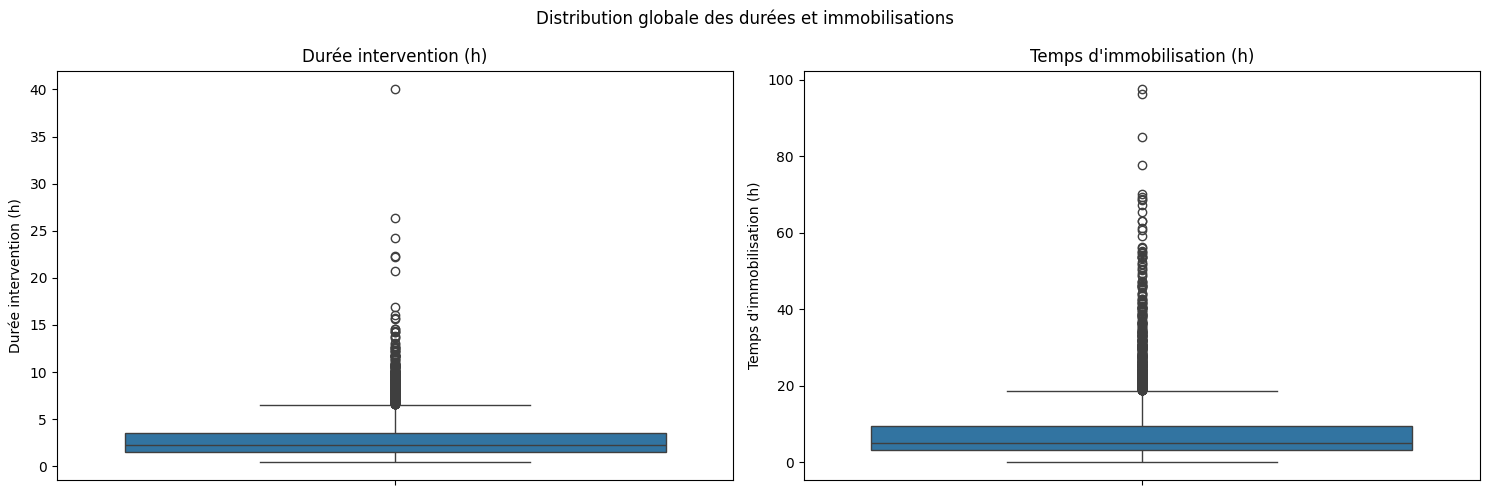

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, col in zip(axes, cols_temps):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.suptitle("Distribution globale des durées et immobilisations")
plt.tight_layout()
plt.show()

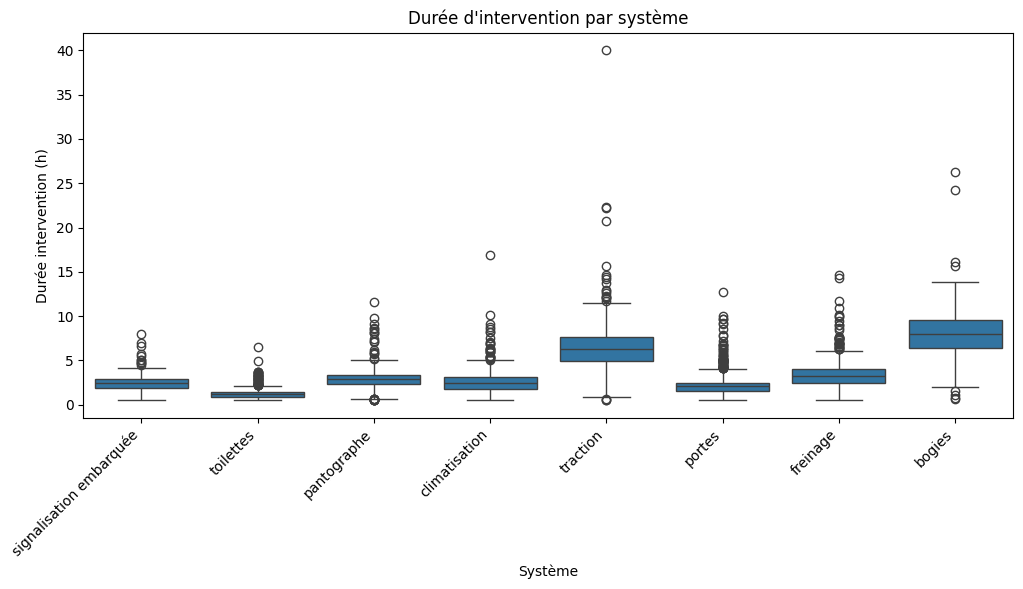

In [16]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x="Système", y="Durée intervention (h)")
plt.title("Durée d'intervention par système")
plt.xticks(rotation=45, ha="right")
plt.show()

**Lecture :**
- Le boxplot global est trompeur : une grande partie des points « extrêmes » globaux correspondent à des interventions **normales** sur des systèmes lourds (traction et bogies ont une médiane d'environ 6 à 8 h).
- Par système : interventions courtes et prévisibles sur les toilettes, portes et signalisation ; longues et variables sur la traction et les bogies, ce qui est cohérent avec le métier (organes lourds, souvent déposés).

In [17]:
# Nombre de valeurs extrêmes (règle 1,5 × écart interquartile) par système
def nb_extremes(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return ((s > q3 + 1.5 * (q3 - q1)) | (s < q1 - 1.5 * (q3 - q1))).sum()

df.groupby("Système")["Durée intervention (h)"].apply(nb_extremes).sort_values(ascending=False)

Système
portes                     58
toilettes                  40
freinage                   34
pantographe                28
climatisation              27
traction                   20
signalisation embarquée    11
bogies                      8
Name: Durée intervention (h), dtype: int64

In [18]:
# Examen des plus longues interventions, ligne par ligne
df.nlargest(10, "Durée intervention (h)")[
    ["Système", "Type intervention", "Durée intervention (h)",
     "Temps d'immobilisation (h)", "Coût (€)", "Commentaire"]]

,Système,Type intervention,Durée intervention (h),Temps d'immobilisation (h),Coût (€),Commentaire
1396,traction,corrective,40.0,46.0,8299.0,Défaut onduleur
3353,bogies,corrective,26.3,31.8,5077.0,Bruit anormal essieu
3202,bogies,corrective,24.2,29.7,3782.0,Bruit anormal essieu
2118,traction,corrective,22.3,30.6,5604.0,Défaut onduleur
222,traction,corrective,22.2,22.9,6412.0,Disjonction traction
2443,traction,corrective,20.7,38.8,NaN,Défaut onduleur
1055,climatisation,corrective,16.9,22.9,1856.0,Fuite de gaz réfrigérant
1569,bogies,corrective,16.1,34.9,4287.0,Fissure détectée
4096,traction,corrective,15.7,23.9,5526.0,Défaut onduleur
1977,bogies,corrective,15.6,23.3,3641.0,Bruit anormal essieu


**Décision :**
- En **nombre**, les portes, les toilettes et le freinage ont le plus de valeurs extrêmes, en partie parce qu'ils ont le plus d'interventions.
- En **éloignement**, la traction (40 h) et les bogies (environ 25 h) se détachent nettement.
- Ces longues interventions sont toutes des **correctives** sur des organes lourds, avec une immobilisation supérieure à la durée et un coût à la hauteur : elles sont cohérentes. **Je les conserve**, ce sont de vraies grosses réparations.

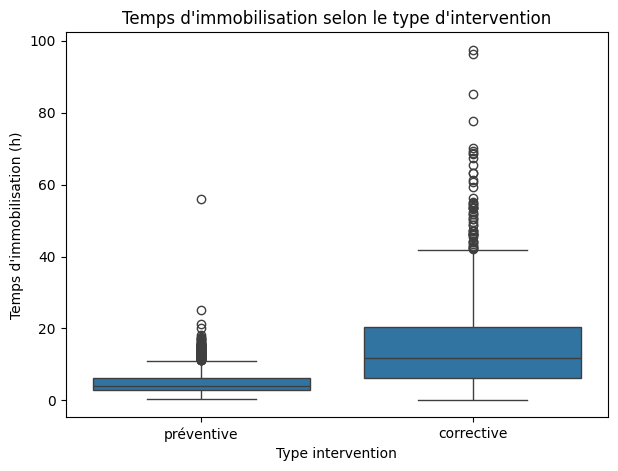

In [19]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Type intervention", y="Temps d'immobilisation (h)")
plt.title("Temps d'immobilisation selon le type d'intervention")
plt.show()

**Lecture :**
- Une corrective immobilise la rame environ **trois fois plus longtemps** qu'une préventive (médiane d'environ 12 h contre environ 4 h).
- Les correctives sont beaucoup moins prévisibles, et toutes les très longues immobilisations sont des correctives.
- Explication métier : une préventive est planifiée (pièces et équipes prêtes), une corrective demande un diagnostic et souvent une attente de pièces.
- **Une préventive isolée dépasse 50 h** : anomalie à examiner (section suivante).

## 7. Mislabelled intervention types – Types d'intervention mal étiquetés

In [20]:
# La préventive suspecte
df[(df["Type intervention"] == "préventive") & (df["Temps d'immobilisation (h)"] > 30)]

,Matériel,Système,Date intervention,Type intervention,Durée intervention (h),Panne associée,Temps d'immobilisation (h),Coût (€),Technicien,Commentaire,valeur_neg
799,R016,climatisation,2024-05-24,préventive,2.2,oui,56.1,813.0,Équipe mobile Nord,Compresseur remplacé,False


In [21]:
# Quelles équipes font des préventives ?
pd.crosstab(df["Technicien"], df["Type intervention"])

Type intervention,corrective,préventive
Technicien,,
Atelier Lyon-Perrache,250,1334
Atelier Vénissieux,376,1395
Équipe mobile Nord,315,4
Équipe mobile Sud,295,3


La préventive suspecte porte le commentaire « Compresseur remplacé » et a été réalisée par une **équipe mobile**. Or les équipes mobiles ne font quasiment jamais de préventive (environ 1 % de leurs interventions). Tout indique une **panne réparée**, donc une corrective mal étiquetée : le problème vient du type, pas de l'immobilisation (56 h est plausible pour un remplacement de compresseur).

Pour trouver tous les cas similaires, le commentaire est un meilleur détecteur que le technicien : on cherche les interventions dont le commentaire est typique de l'autre type.

In [22]:
tab = pd.crosstab(df["Commentaire"], df["Type intervention"])
com_correctifs = tab[tab["corrective"] > tab["préventive"]].index
com_preventifs = tab[tab["préventive"] > tab["corrective"]].index

# Préventives portant un commentaire de panne
mal_prev = df[(df["Type intervention"] == "préventive") & df["Commentaire"].isin(com_correctifs)]
# Correctives portant un commentaire de visite planifiée
mal_cor = df[(df["Type intervention"] == "corrective") & df["Commentaire"].isin(com_preventifs)]

print("Préventives à reclasser en correctives :", len(mal_prev))
print("Correctives à reclasser en préventives :", len(mal_cor))
pd.concat([mal_prev, mal_cor])[["Technicien", "Système", "Type intervention", "Commentaire"]]

Préventives à reclasser en correctives : 11
Correctives à reclasser en préventives : 7


,Technicien,Système,Type intervention,Commentaire
272,Équipe mobile Sud,portes,préventive,Porte bloquée
799,Équipe mobile Nord,climatisation,préventive,Compresseur remplacé
921,Équipe mobile Sud,climatisation,préventive,Compresseur remplacé
1285,Équipe mobile Nord,climatisation,préventive,Clim HS en voiture 2
1327,Atelier Lyon-Perrache,portes,préventive,Porte bloquée
2716,Équipe mobile Nord,climatisation,préventive,Fuite de gaz réfrigérant
3084,Équipe mobile Nord,traction,préventive,Disjonction traction
3373,Atelier Vénissieux,toilettes,préventive,WC hors service
3493,Atelier Lyon-Perrache,portes,préventive,Capteur de fermeture HS
3523,Équipe mobile Sud,climatisation,préventive,Compresseur remplacé


**Décision :** le commentaire décrit sans ambiguïté la nature de l'intervention (une panne ou une visite planifiée), et pour les préventives concernées, la plupart ont été faites par une équipe mobile. Je reclasse ces interventions selon leur commentaire et les trace dans la colonne `type_corrige`.

In [23]:
df["type_corrige"] = df.index.isin(mal_prev.index.union(mal_cor.index))
df.loc[mal_prev.index, "Type intervention"] = "corrective"
df.loc[mal_cor.index, "Type intervention"] = "préventive"

print("Lignes reclassées :", df["type_corrige"].sum())
pd.crosstab(df["Technicien"], df["Type intervention"])   # équipes mobiles : 0 préventive

Lignes reclassées : 18


Type intervention,corrective,préventive
Technicien,,
Atelier Lyon-Perrache,247,1337
Atelier Vénissieux,376,1395
Équipe mobile Nord,319,0
Équipe mobile Sud,298,0


## 8. Costs – Coûts aberrants

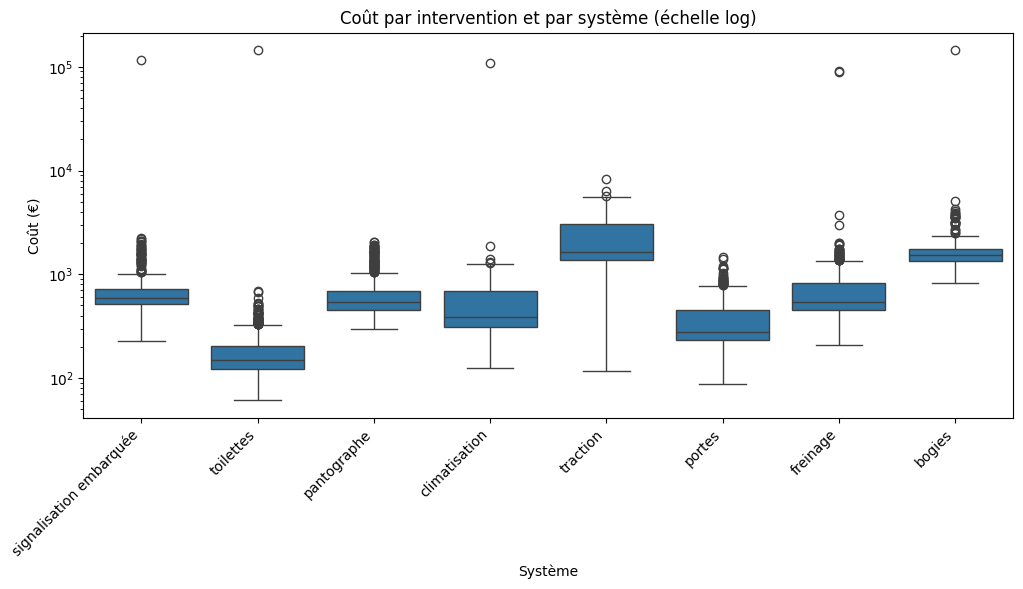

In [24]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x="Système", y="Coût (€)")
plt.yscale("log")   # échelle logarithmique : chaque graduation multiplie par 10
plt.title("Coût par intervention et par système (échelle log)")
plt.xticks(rotation=45, ha="right")
plt.show()

In [25]:
df.nlargest(10, "Coût (€)")[["Système", "Type intervention", "Durée intervention (h)", "Coût (€)", "Commentaire"]]

,Système,Type intervention,Durée intervention (h),Coût (€),Commentaire
682,toilettes,préventive,1.1,144085.0,Visite périodique
1008,bogies,préventive,3.5,143965.0,Visite périodique
2070,signalisation embarquée,corrective,2.8,117348.0,Perte liaison radio
432,climatisation,corrective,2.4,108177.0,Compresseur remplacé
3651,freinage,préventive,3.4,91423.0,Visite périodique
2952,freinage,préventive,3.5,89976.0,Remplacement préventif pièces d'usure
1396,traction,corrective,40.0,8299.0,Défaut onduleur
222,traction,corrective,22.2,6412.0,Disjonction traction
2956,traction,corrective,12.1,5696.0,Défaut onduleur
2118,traction,corrective,22.3,5604.0,Défaut onduleur


In [26]:
# Référence : coût horaire médian par système
df["cout_par_heure"] = df["Coût (€)"] / df["Durée intervention (h)"]
df.groupby("Système")["cout_par_heure"].median().round(0).sort_values()

Système
toilettes                  122.0
portes                     135.0
climatisation              159.0
freinage                   164.0
bogies                     184.0
pantographe                192.0
signalisation embarquée    248.0
traction                   262.0
Name: cout_par_heure, dtype: float64

**Lecture :**
- Le coût horaire médian va d'environ 120 €/h (toilettes) à environ 260 €/h (traction) : tous les systèmes restent dans une plage d'un facteur 2.
- Le tableau des plus gros coûts montre une **rupture nette** : 6 interventions courtes (1 à 3,5 h), dont des visites périodiques, coûtent entre 90 000 et 144 000 €, soit plusieurs centaines de fois le coût horaire normal de leur système. Juste après, les coûts chutent sous 8 300 € et correspondent à de longues correctives de traction, cohérentes (40 h × environ 260 €/h ≈ 10 000 €).

**Décision :** les 6 coûts au-dessus de la rupture sont des erreurs de saisie, remplacés par NaN. Le seuil de 50 000 € est placé dans la rupture.

In [27]:
seuil = 50000
df["cout_aberrant"] = df["Coût (€)"] > seuil
df["Coût (€)"] = df["Coût (€)"].mask(df["cout_aberrant"])

print("Coûts aberrants corrigés :", df["cout_aberrant"].sum())

Coûts aberrants corrigés : 6


## 9. Cross-column inconsistencies – Incohérences entre colonnes

**Règle métier :** pendant une intervention, la rame est forcément à l'arrêt. Le temps d'immobilisation doit donc toujours être **supérieur ou égal** à la durée d'intervention. Ce type d'erreur n'apparaît sur aucun boxplot : chaque valeur, prise seule, paraît normale.

In [28]:
incoherences = df[df["Temps d'immobilisation (h)"] < df["Durée intervention (h)"]]
print("Lignes incohérentes :", len(incoherences))
print(incoherences["Système"].value_counts())

# Rapport immobilisation / durée sur ces lignes
(incoherences["Temps d'immobilisation (h)"] / incoherences["Durée intervention (h)"]).round(1).value_counts()

Lignes incohérentes : 19
Système
toilettes                  4
portes                     4
climatisation              3
freinage                   3
pantographe                2
bogies                     1
traction                   1
signalisation embarquée    1
Name: count, dtype: int64


0.5    18
0.4     1
Name: count, dtype: int64

**Lecture :** sur toutes ces lignes, l'immobilisation vaut **la moitié de la durée**. Un rapport constant n'est pas une saisie au hasard : c'est une **erreur systématique** (calcul ou formule erronés), à signaler au responsable des données. Les durées sont cohérentes avec leur système : c'est donc l'immobilisation qui est fausse.

**Décision :** remplacement par NaN plutôt que reconstruction (multiplier par 2 donnerait une immobilisation égale à la durée, probablement sous-estimée). Les lignes concernées sont réparties sur tous les systèmes : pas de biais introduit.

In [29]:
df["immo_incoherente"] = df.index.isin(incoherences.index)
df.loc[incoherences.index, "Temps d'immobilisation (h)"] = np.nan

print("Incohérences restantes :", (df["Temps d'immobilisation (h)"] < df["Durée intervention (h)"]).sum())

Incohérences restantes : 0


## 10. Missing values – Valeurs manquantes

In [30]:
bilan = pd.DataFrame({"nb_NaN": df.isnull().sum(),
                      "pct_NaN": (df.isnull().mean() * 100).round(1)})
bilan[bilan["nb_NaN"] > 0]

,nb_NaN,pct_NaN
Durée intervention (h),89,2.2
Temps d'immobilisation (h),80,2.0
Coût (€),126,3.1
Technicien,81,2.0
Commentaire,202,5.0
cout_par_heure,205,5.1


In [31]:
# Répartition des NaN numériques par système (en %)
cols_num = ["Durée intervention (h)", "Temps d'immobilisation (h)", "Coût (€)"]
(df.groupby("Système")[cols_num].apply(lambda g: g.isnull().mean() * 100)).round(1)

,Durée intervention (h),Temps d'immobilisation (h),Coût (€)
Système,,,
bogies,2.7,1.8,4.1
climatisation,1.8,2.6,2.2
freinage,1.5,2.8,1.8
pantographe,1.2,2.5,4.1
portes,2.4,1.2,3.2
signalisation embarquée,2.7,1.8,2.4
toilettes,2.7,2.0,3.8
traction,2.8,1.1,3.2


**Lecture :** les valeurs manquantes représentent quelques pourcents par colonne et sont réparties sur tous les systèmes : leur impact sur l'analyse est limité.

**Décisions :**
- **Durée, immobilisation, coût :** NaN conservés. Les calculs pandas les ignorent automatiquement ; l'imputation (médiane par système et type d'intervention) sera faite au moment de la modélisation.
- **Technicien :** remplacé par la catégorie « Inconnu ». Le type d'intervention ne permet pas de deviner l'équipe de façon fiable, et « Inconnu » n'invente aucune information.
- **Commentaire :** non complété. Il n'est pas utilisé par le modèle, mais il a été précieux au nettoyage (détection des types mal étiquetés).

In [32]:
df["Technicien"] = df["Technicien"].fillna("Inconnu")
df["Technicien"].value_counts()

Technicien
Atelier Vénissieux       1771
Atelier Lyon-Perrache    1584
Équipe mobile Nord        319
Équipe mobile Sud         298
Inconnu                    81
Name: count, dtype: int64

## 11. Summary & export – Récapitulatif et export

In [33]:
df = df.drop(columns=["cout_par_heure"])

recap = pd.Series({
    "Doublons supprimés": nb_doublons,
    "Durées/immobilisations négatives → NaN": df["valeur_neg"].sum(),
    "Types d'intervention reclassés": df["type_corrige"].sum(),
    "Coûts aberrants → NaN": df["cout_aberrant"].sum(),
    "Immobilisations incohérentes → NaN": df["immo_incoherente"].sum(),
}, name="Nombre de lignes")
recap

Doublons supprimés                        45
Durées/immobilisations négatives → NaN     8
Types d'intervention reclassés            18
Coûts aberrants → NaN                      6
Immobilisations incohérentes → NaN        19
Name: Nombre de lignes, dtype: int64

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4053 entries, 0 to 4097
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Matériel                    4053 non-null   object        
 1   Système                     4053 non-null   object        
 2   Date intervention           4053 non-null   datetime64[ns]
 3   Type intervention           4053 non-null   object        
 4   Durée intervention (h)      3964 non-null   float64       
 5   Panne associée              4053 non-null   object        
 6   Temps d'immobilisation (h)  3973 non-null   float64       
 7   Coût (€)                    3927 non-null   float64       
 8   Technicien                  4053 non-null   object        
 9   Commentaire                 3851 non-null   object        
 10  valeur_neg                  4053 non-null   bool          
 11  type_corrige                4053 non-null   bool          
 1

Le fichier exporté contient les données nettoyées et les **colonnes de traçabilité** (`valeur_neg`, `type_corrige`, `cout_aberrant`, `immo_incoherente`), qui permettent de retrouver chaque correction.

In [35]:
df.to_csv("maintenance_rames_clean.csv", sep=";", decimal=",", index=False)